In [1]:

import numpy as np
import numba
from numba import cuda, njit, vectorize, float64, int32, float32
import math
import matplotlib.pyplot as plt


print(np.__version__)
print(numba.__version__)

cuda.detect()

2.1.3
0.61.0
Found 1 CUDA devices
id 0    b'NVIDIA GeForce RTX 3060 Laptop GPU'                              [SUPPORTED]
                      Compute Capability: 8.6
                           PCI Device ID: 0
                              PCI Bus ID: 1
                                    UUID: GPU-ab07a219-12ec-be5b-c280-77dd81f42933
                                Watchdog: Enabled
             FP32/FP64 Performance Ratio: 32
Summary:
	1/1 devices are supported


True

# Test vectorize

In [23]:
from numba import vectorize, float64

@cuda.jit(device=True)
def f(mat_val, x, y, weight):
    return mat_val * (weight * (x + y))

In [24]:
@cuda.jit
def vect_operation(matrix, matrix_output, weight):
    x, y = cuda.grid(2)

    if x < matrix.shape[0] and y < matrix.shape[1]:
        matrix_output[x, y] = f(float64(matrix[x, y]), int32(x), int32(y), float32(weight))

In [ ]:
mouse_data = np.load('/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/concat/1760_concat_matrix_test.npy')
nz, nx, na, nt = mouse_data.shape

mouse_data_gpu = cuda.to_device(np.reshape(mouse_data, (nz * nx, na, nt)))

In [3]:
del mouse_data

In [65]:
%%time

threadsperblock = (32, 32)
blockspergrid_x = (mouse_data.shape[1] + (threadsperblock[0] - 1)) // threadsperblock[0]
blockspergrid_y = (mouse_data.shape[0] + (threadsperblock[1] - 1)) // threadsperblock[1]

blockspergrid = (blockspergrid_x, blockspergrid_y)

output_matrix = np.zeros_like(mouse_data)
output_matrix_gpu = cuda.to_device(output_matrix)

vect_operation[blockspergrid, threadsperblock](mouse_data_gpu, output_matrix_gpu, 0.5)

output_matrix = output_matrix_gpu.copy_to_host()

CPU times: user 2.2 ms, sys: 264 μs, total: 2.46 ms
Wall time: 1.83 ms


In [74]:
tst = np.array([[1,2],[3,4]])
tst

array([[1, 2],
       [3, 4]])

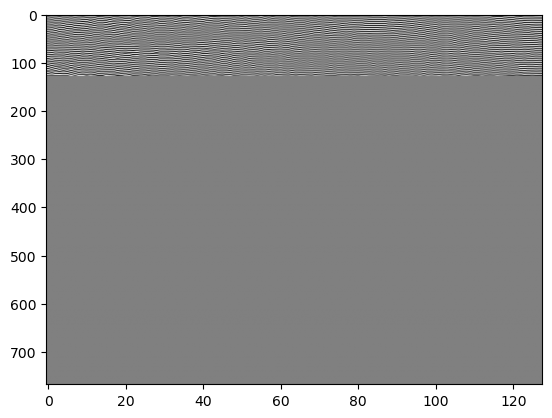

In [15]:
plt.imshow(output_matrix, cmap='gray', aspect='auto')

# Test 0

In [11]:
mouse_data = np.load('/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/concat/concatenated_matrix.npy')

mouse_data_cuda = cuda.to_device(mouse_data)

In [30]:
%%time

memmap_mouse_data = np.lib.format.open_memmap('/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/concat/concatenated_matrix.npy', mode='r')
memmap_mouse_data_frames = memmap_mouse_data[:,:,:,0:3].copy()

memmap_mouse_data_cuda = cuda.to_device(memmap_mouse_data_frames)
memmap_mouse_data_cuda.alloc_size 

CPU times: user 38.4 ms, sys: 138 ms, total: 176 ms
Wall time: 175 ms


9437184

# Test 1

In [31]:
ex_matrix = np.ones((1000, 20000), dtype=np.float32)

ex_matrix_cuda = cuda.to_device(ex_matrix)
gpu_output = cuda.to_device(np.zeros_like(ex_matrix))

In [32]:


def matrix_operation(matrix):

    result = np.zeros_like(matrix)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            if j > i:
                result[i, j] = matrix[i, j] * 2 + 1
    return result

In [33]:
@njit(parallel=True, fastmath=True)
def test_op(a,b):
    return a + b

@cuda.jit
def matrix_operation_gpu(matrix, result):
    i, j = cuda.grid(2)
    test_op(i,j)
    if i < matrix.shape[0] and j < matrix.shape[1]:
        if j > i:
            result[i, j] = matrix[i, j] * 2 + 1
        else:
            result[i, j] = 0


In [34]:
%%time
res_matrix = matrix_operation(ex_matrix)

CPU times: user 4.86 s, sys: 0 ns, total: 4.86 s
Wall time: 4.86 s


In [ ]:
%%time

threads_per_block = (16, 16)
blocks_per_grid_x = math.ceil(ex_matrix.shape[0] / threads_per_block[0])
blocks_per_grid_y = math.ceil(ex_matrix.shape[1] / threads_per_block[1])

matrix_operation_gpu[(blocks_per_grid_x, blocks_per_grid_y), threads_per_block](ex_matrix_cuda, gpu_output)
res_matrix_gpu = gpu_output.copy_to_host()

CPU times: user 76.8 ms, sys: 20.2 ms, total: 97 ms
Wall time: 102 ms


In [36]:
print(np.all(res_matrix == res_matrix_gpu))

True


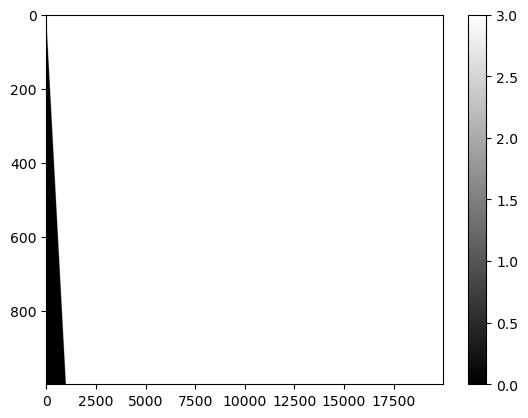

In [37]:
plt.imshow(res_matrix, cmap='gray', aspect='auto')   
plt.colorbar()
plt.show() 

# Example 1

## CPU

In [38]:
random_array = np.random.random((60_000_000))

In [39]:
output = np.zeros_like(random_array)

In [40]:
%%time

def foo(i):
    output[i] = random_array[i] * 2
    
[foo(i) for i in range(len(random_array))]

output

CPU times: user 9.21 s, sys: 140 ms, total: 9.36 s
Wall time: 9.35 s


array([1.75467917, 0.3947371 , 1.63582933, ..., 1.35400311, 1.52714026,
       0.43025402])

## GPU

In [41]:
%%time

output = np.zeros_like(random_array)

threads = 128
blocks = math.ceil(random_array.shape[0] / threads)

@cuda.jit
def foo(input_array, output_array):
    i = cuda.grid(1)
    output_array[i] = input_array[i] * 2
    
foo[blocks, threads](random_array, output)
output

/home/matmat/miniconda3/envs/superresolution/lib/python3.13/site-packages/numba/cuda/cudadrv/devicearray.py:887: NumbaPerformanceWarning: Host array used in CUDA kernel will incur copy overhead to/from device.
  warn(NumbaPerformanceWarning(msg))


CPU times: user 441 ms, sys: 43.9 ms, total: 485 ms
Wall time: 485 ms


array([1.75467917, 0.3947371 , 1.63582933, ..., 1.35400311, 1.52714026,
       0.43025402])